# Exploratory Data Analysis: Crime Patterns in Chicago (2017)

**Base paper:** Garcia-Zanabria et al. (2021), *CrimAnalyzer: Understanding
Crime Patterns in São Paulo*, IEEE Transactions on Visualization and
Computer Graphics.

**Dataset:** *Crimes -- 2001 to Present* (id `ijzp-q8t2`), City of Chicago
Data Portal. This notebook uses the January 1 -- August 25, 2017 extract
(172,327 records).

This notebook performs the full exploratory analysis behind the written
report: data loading, cleaning, attribute profiling, four research
hypotheses, and an NMF-based spatio-temporal pattern analysis that extends
the standard aggregate heatmap view, following the hotspot-detection
approach used in CrimAnalyzer.


## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.decomposition import NMF

sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.dpi"] = 130

OUTPUT_DIR = Path("outputs")
FIGURES_DIR = OUTPUT_DIR / "figures"
TABLES_DIR = OUTPUT_DIR / "tables"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

DATA_PATH = "dataset/Crimes_-_2001_to_Present_20260911.csv"
RANDOM_STATE = 42


## 2. Data loading

The dataset is the official Chicago Police Department extract published on
the Chicago Data Portal. Coordinates are withheld for a small share of
records that were never geocoded; this is handled explicitly in Section 4.


In [2]:
df_raw = pd.read_csv(DATA_PATH)
print(f"Records: {len(df_raw):,}   Columns: {df_raw.shape[1]}")
df_raw.head()


Records: 8,636,476   Columns: 22


,ID,Case Number,Date,Block,IUCR,Primary Type,Description,Location Description,Arrest,Domestic,...,Ward,Community Area,FBI Code,X Coordinate,Y Coordinate,Year,Updated On,Latitude,Longitude,Location
0,14315255,JK398108,09/03/2026 12:00:00 AM,070XX S FAIRFIELD AVE,0498,BATTERY,"AGG. DOMESTIC BATTERY - HANDS, FISTS, FEET, SE...",RESIDENCE,False,True,...,17.0,66.0,04B,1159260.0,1857750.0,2026,09/10/2026 03:53:03 PM,41.765386,-87.691824,"(41.765385733, -87.691823541)"
1,14315392,JK398216,09/03/2026 12:00:00 AM,068XX S WESTERN AVE,1310,CRIMINAL DAMAGE,TO PROPERTY,DAY CARE CENTER,False,False,...,16.0,66.0,14,1161556.0,1859189.0,2026,09/10/2026 03:53:03 PM,41.769287,-87.683368,"(41.769287256, -87.683368075)"
2,14315233,JK398112,09/03/2026 12:00:00 AM,0000X E PEARSON ST,0560,ASSAULT,SIMPLE,RESIDENCE,False,False,...,42.0,8.0,08A,1176455.0,1906042.0,2026,09/10/2026 03:53:03 PM,41.897534,-87.627344,"(41.89753369, -87.627343939)"
3,14315892,JK398470,09/03/2026 12:00:00 AM,009XX W WELLINGTON AVE,0312,ROBBERY,ARMED - KNIFE / CUTTING INSTRUMENT,CTA TRAIN,False,False,...,44.0,6.0,03,1169423.0,1920111.0,2026,09/10/2026 03:53:03 PM,41.936296,-87.652761,"(41.936295672, -87.652761369)"
4,14315904,JK398881,09/03/2026 12:00:00 AM,036XX N HAMLIN AVE,0486,BATTERY,DOMESTIC BATTERY SIMPLE,RESIDENCE,True,True,...,30.0,16.0,08B,1150412.0,1923945.0,2026,09/10/2026 03:53:03 PM,41.947209,-87.722529,"(41.947209355, -87.722528621)"


In [3]:
df_raw.dtypes


ID                        int64
Case Number                 str
Date                        str
Block                       str
IUCR                        str
Primary Type                str
Description                 str
Location Description        str
Arrest                     bool
Domestic                   bool
Beat                      int64
District                float64
Ward                    float64
Community Area          float64
FBI Code                    str
X Coordinate            float64
Y Coordinate            float64
Year                      int64
Updated On                  str
Latitude                float64
Longitude               float64
Location                    str
dtype: object

## 3. Data wrangling

`Date` arrives as text and is parsed into a proper datetime, from which
`Hour`, `DayOfWeek`, and `Month` are derived. `Arrest` and `Domestic` are
also recoded to 0/1 for use in correlation and hypothesis-testing steps
later on.


In [4]:
df = df_raw.copy()

df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y %I:%M:%S %p")
df["Hour"] = df["Date"].dt.hour
df["DayOfWeek"] = df["Date"].dt.day_name()
df["Month"] = df["Date"].dt.month

WEEKDAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday",
                 "Friday", "Saturday", "Sunday"]

df["ArrestFlag"] = df["Arrest"].astype(int)
df["DomesticFlag"] = df["Domestic"].astype(int)

print("Date range:", df["Date"].min(), "to", df["Date"].max())


Date range: 2001-01-01 00:00:00 to 2026-09-03 00:00:00


## 4. Data quality assessment

### 4.1 Missing values


In [5]:
null_counts = df_raw.isnull().sum()
null_pct = (null_counts / len(df_raw) * 100).round(2)
null_summary = (pd.DataFrame({"nulls": null_counts, "pct": null_pct})
                .query("nulls > 0")
                .sort_values("nulls", ascending=False))
null_summary.to_csv(TABLES_DIR / "missing_values.csv")
null_summary


,nulls,pct
Ward,614811,7.12
Community Area,613722,7.11
Longitude,99997,1.16
X Coordinate,99997,1.16
Y Coordinate,99997,1.16
Location,99997,1.16
Latitude,99997,1.16
Location Description,16641,0.19
District,47,0.00


### 4.2 Duplicate records

In [6]:
print("Duplicate IDs:", df["ID"].duplicated().sum())
print("Fully duplicated rows:", df.duplicated().sum())

# Case Number is expected to be unique per incident, with one documented
# exception: homicide victims are logged one row per victim, so a single
# case can legitimately span more than one record.
dup_cases = df[df.duplicated("Case Number", keep=False)]
print("\nRows sharing a Case Number:", len(dup_cases))
print("Distinct cases involved:", dup_cases["Case Number"].nunique())
print(dup_cases["Primary Type"].value_counts())


Duplicate IDs: 0
Fully duplicated rows: 0

Rows sharing a Case Number: 1154
Distinct cases involved: 525
Primary Type
HOMICIDE    1154
Name: count, dtype: int64


### 4.3 Out-of-domain values

In [7]:
print("Records with District == 31 (non-patrol administrative code):",
      (df["District"] == 31).sum())
print("Records with Community Area == 0 (outside the valid 1-77 range):",
      (df["Community Area"] == 0).sum())

# Excluded only from spatial aggregations, not from the full dataset.
df_spatial = df[(df["District"] != 31) & (df["Community Area"] != 0)].copy()


Records with District == 31 (non-patrol administrative code): 289
Records with Community Area == 0 (outside the valid 1-77 range): 2644


### 4.4 Timestamp capture artifact

A disproportionate share of incidents are logged at exactly 12:00:00 PM
compared to a neighboring hour, which points to noon being used as a
default timestamp when the exact time of an incident is unknown.


In [8]:
noon = df[df["Hour"] == 12]
control = df[df["Hour"] == 13]

noon_exact = ((noon["Date"].dt.minute == 0) & (noon["Date"].dt.second == 0)).mean()
control_exact = ((control["Date"].dt.minute == 0) & (control["Date"].dt.second == 0)).mean()

print(f"Share of 12:00 hour records logged at an exact minute/second: {noon_exact:.1%}")
print(f"Same share for the 13:00 hour (control): {control_exact:.1%}")


Share of 12:00 hour records logged at an exact minute/second: 41.0%
Same share for the 13:00 hour (control): 29.5%


## 5. Attribute profile

### 5.1 Full attribute table


In [9]:
profile = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "n_unique": df_raw.nunique(),
    "n_null": df_raw.isnull().sum(),
})
profile["null_pct"] = (profile["n_null"] / len(df_raw) * 100).round(2)
profile.to_csv(TABLES_DIR / "attribute_profile.csv")
profile


,dtype,n_unique,n_null,null_pct
ID,int64,8636476,0,0.00
Case Number,str,8635847,0,0.00
Date,str,3630567,0,0.00
Block,str,66123,0,0.00
IUCR,str,418,0,0.00
Primary Type,str,34,0,0.00
Description,str,570,0,0.00
Location Description,str,218,16641,0.19
Arrest,bool,2,0,0.00
Domestic,bool,2,0,0.00


### 5.2 Descriptive statistics for numeric / coded attributes

In [10]:
numeric_cols = ["Hour", "Beat", "District", "Ward", "Community Area",
                "Latitude", "Longitude"]
descriptive_stats = df[numeric_cols].describe(percentiles=[.25, .5, .75]).T
descriptive_stats["skew"] = df[numeric_cols].skew()
descriptive_stats.to_csv(TABLES_DIR / "descriptive_statistics.csv")
descriptive_stats.round(2)


,count,mean,std,min,25%,50%,75%,max,skew
Hour,8636476.0,13.05,6.77,0.00,9.00,14.00,19.00,23.00,-0.44
Beat,8636476.0,1184.05,708.81,111.00,621.00,1034.00,1731.00,6100.00,0.47
District,8636429.0,11.31,7.02,1.00,6.00,10.00,17.00,61.00,0.51
Ward,8021665.0,22.78,13.86,0.00,10.00,23.00,34.00,50.00,0.17
Community Area,8022754.0,37.34,21.55,0.00,23.00,32.00,56.00,77.00,0.19
Latitude,8536479.0,41.84,0.09,36.62,41.77,41.86,41.91,42.02,-3.56
Longitude,8536479.0,-87.67,0.06,-91.69,-87.71,-87.67,-87.63,-87.52,-5.16


### 5.3 Most frequent crime types

In [11]:
df["Primary Type"].value_counts().head(15)


Primary Type
THEFT                         1834108
BATTERY                       1573013
CRIMINAL DAMAGE                980945
NARCOTICS                      769557
ASSAULT                        582905
OTHER OFFENSE                  539626
BURGLARY                       457299
MOTOR VEHICLE THEFT            447160
DECEPTIVE PRACTICE             402157
ROBBERY                        318870
CRIMINAL TRESPASS              231620
WEAPONS VIOLATION              129312
PROSTITUTION                    70553
OFFENSE INVOLVING CHILDREN      62652
PUBLIC PEACE VIOLATION          55877
Name: count, dtype: int64

## 6. Relationships between attributes

Pearson and Spearman correlations are computed across the numeric / coded
attributes. `Beat` and `District` are expected to correlate almost
perfectly, since `Beat` is a finer-grained subdivision nested inside
`District`.


In [12]:
corr_cols = ["Beat", "District", "Ward", "Community Area",
             "Hour", "ArrestFlag", "DomesticFlag"]
pearson_corr = df[corr_cols].corr(method="pearson")
spearman_corr = df[corr_cols].corr(method="spearman")
pearson_corr.round(2)


,Beat,District,Ward,Community Area,Hour,ArrestFlag,DomesticFlag
Beat,1.00,0.95,0.63,-0.50,-0.01,-0.01,-0.06
District,0.95,1.00,0.67,-0.49,-0.01,-0.02,-0.05
Ward,0.63,0.67,1.00,-0.53,-0.00,-0.01,-0.07
Community Area,-0.50,-0.49,-0.53,1.00,0.00,0.00,0.09
Hour,-0.01,-0.01,-0.00,0.00,1.00,0.08,-0.04
ArrestFlag,-0.01,-0.02,-0.01,0.00,0.08,1.00,-0.06
DomesticFlag,-0.06,-0.05,-0.07,0.09,-0.04,-0.06,1.00


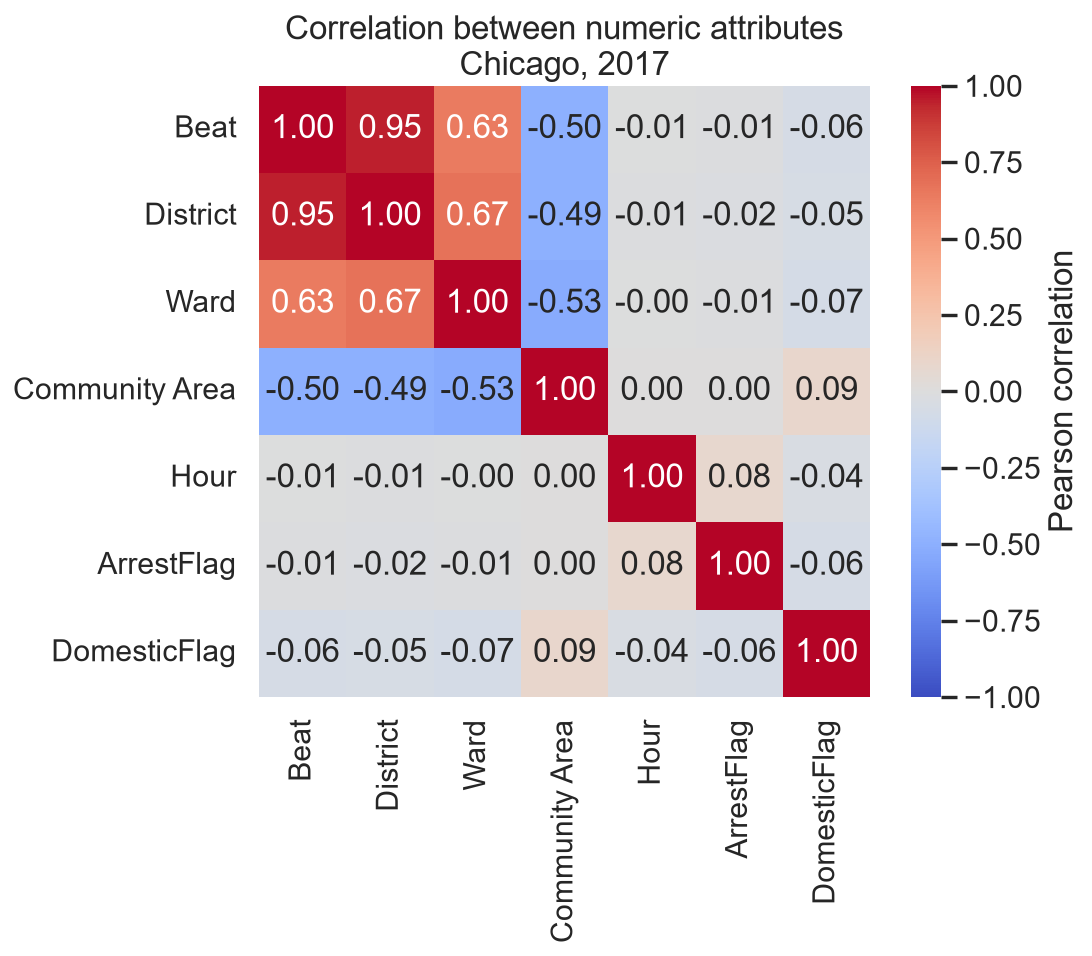

In [13]:
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(pearson_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={"label": "Pearson correlation"})
ax.set_title("Correlation between numeric attributes\nChicago, 2017")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig4_correlation_heatmap.png")
plt.show()


## 7. Hypothesis testing

Four hypotheses are examined, each tied to a specific research question
about spatial concentration, temporal rhythm, clearance rate, and the
relationship between domestic incidents and location type.

### H1 -- Spatial concentration (hotspots)


In [14]:
district_counts = df_spatial["District"].value_counts().sort_values(ascending=False)
top5_share = district_counts.head(5).sum() / district_counts.sum() * 100

print(f"Top 5 districts account for {top5_share:.1f}% of all incidents")
print(district_counts.head(5))
print("\nLowest-volume district:", district_counts.idxmin(), "->", district_counts.min())


Top 5 districts account for 30.1% of all incidents
District
8.0     578031
11.0    545777
6.0     504076
4.0     488468
25.0    486370
Name: count, dtype: int64

Lowest-volume district: 21.0 -> 4


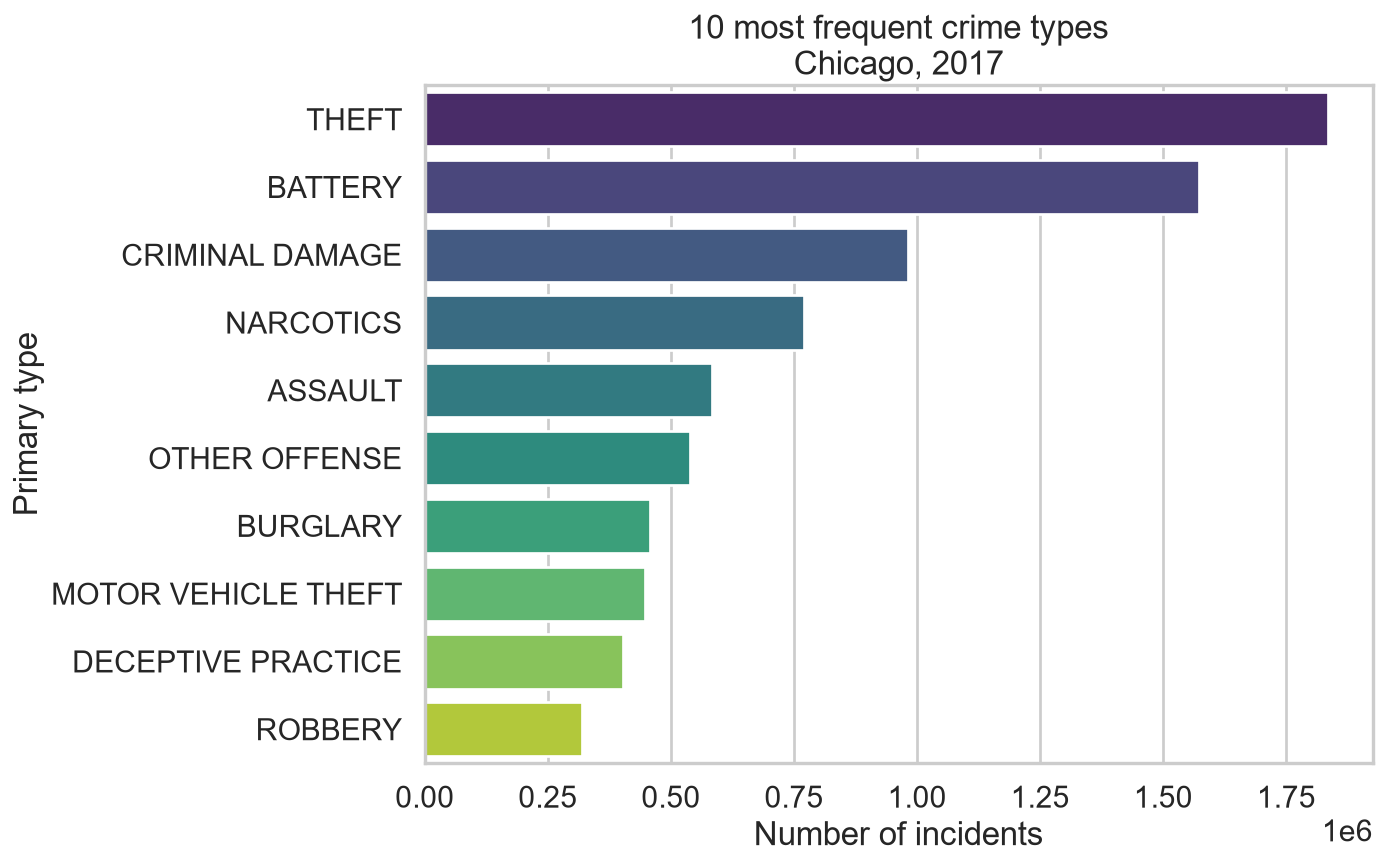

In [15]:
top10_types = df["Primary Type"].value_counts().head(10)

fig, ax = plt.subplots(figsize=(11, 7))
sns.barplot(x=top10_types.values, y=top10_types.index,
            hue=top10_types.index, palette="viridis", legend=False, ax=ax)
ax.set_title("10 most frequent crime types\nChicago, 2017")
ax.set_xlabel("Number of incidents")
ax.set_ylabel("Primary type")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig3_top_crime_types.png")
plt.show()


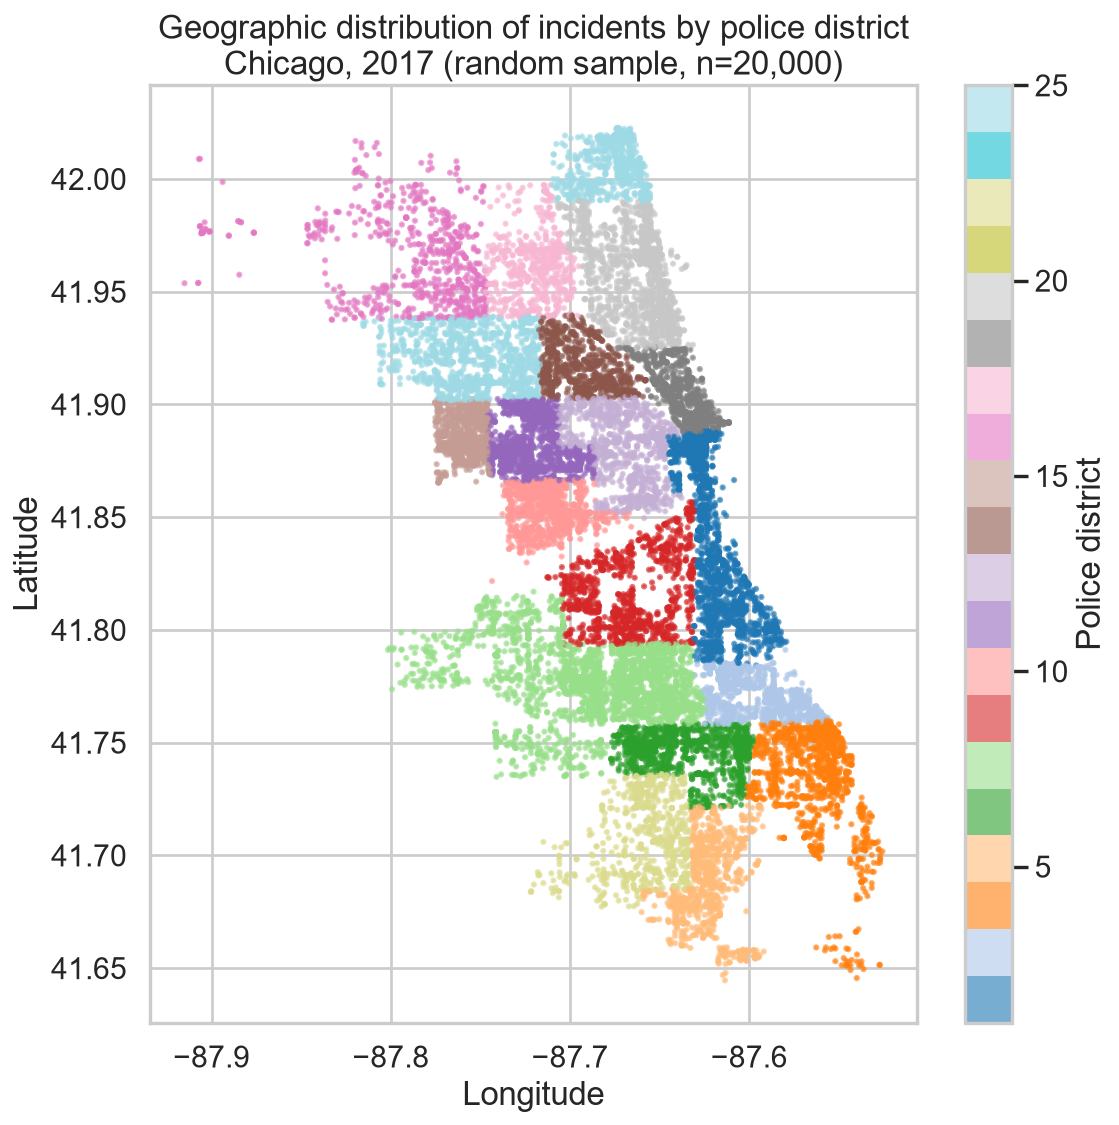

In [16]:
geo_sample = (df_spatial.dropna(subset=["Latitude", "Longitude"])
              .sample(n=20000, random_state=RANDOM_STATE))

fig, ax = plt.subplots(figsize=(9, 9))
scatter = ax.scatter(geo_sample["Longitude"], geo_sample["Latitude"],
                      c=geo_sample["District"], cmap="tab20", s=4, alpha=0.6)
ax.set_title("Geographic distribution of incidents by police district\n"
             "Chicago, 2017 (random sample, n=20,000)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
fig.colorbar(scatter, ax=ax, label="Police district")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig6_district_scatter_map.png")
plt.show()


**Finding.** The five busiest districts account for roughly 30% of all
incidents, confirming a moderate but clear spatial concentration consistent
with the hotspot behavior CrimAnalyzer documents for São Paulo.

### H2 -- Temporal patterns


In [17]:
hourly_counts = df.groupby("Hour").size()
print("Peak hour:", hourly_counts.idxmax(), "->", hourly_counts.max(), "incidents")
print("Lowest hour:", hourly_counts.idxmin(), "->", hourly_counts.min(), "incidents")

# August only covers 25 days in this extract, so daily rate (not raw
# monthly totals) is used to compare months on an equal footing.
days_in_month = {1: 31, 2: 28, 3: 31, 4: 30, 5: 31, 6: 30, 7: 31, 8: 25}
monthly_counts = df.groupby("Month").size()
daily_rate = (monthly_counts / pd.Series(days_in_month)).round(1)
print("\nAverage incidents per day, by month:")
print(daily_rate)


Peak hour: 0 -> 507298 incidents
Lowest hour: 5 -> 122580 incidents

Average incidents per day, by month:
Month
1     21905.1
2     21477.0
3     22933.1
4     23595.1
5     24851.7
6     25648.8
7     26122.3
8     32002.3
9         NaN
10        NaN
11        NaN
12        NaN
dtype: float64


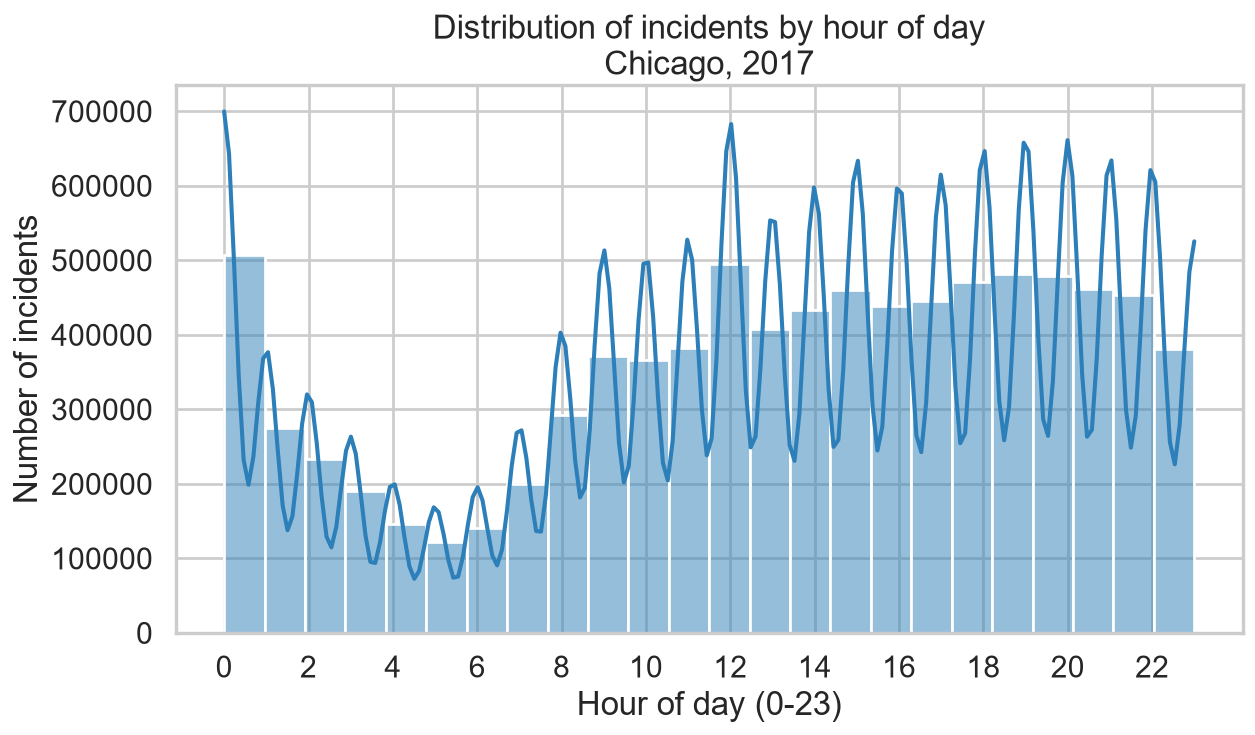

In [18]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(df["Hour"], bins=24, kde=True, color="#2c7fb8", ax=ax)
ax.set_title("Distribution of incidents by hour of day\nChicago, 2017")
ax.set_xlabel("Hour of day (0-23)")
ax.set_ylabel("Number of incidents")
ax.set_xticks(range(0, 24, 2))
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig1_hour_histogram.png")
plt.show()


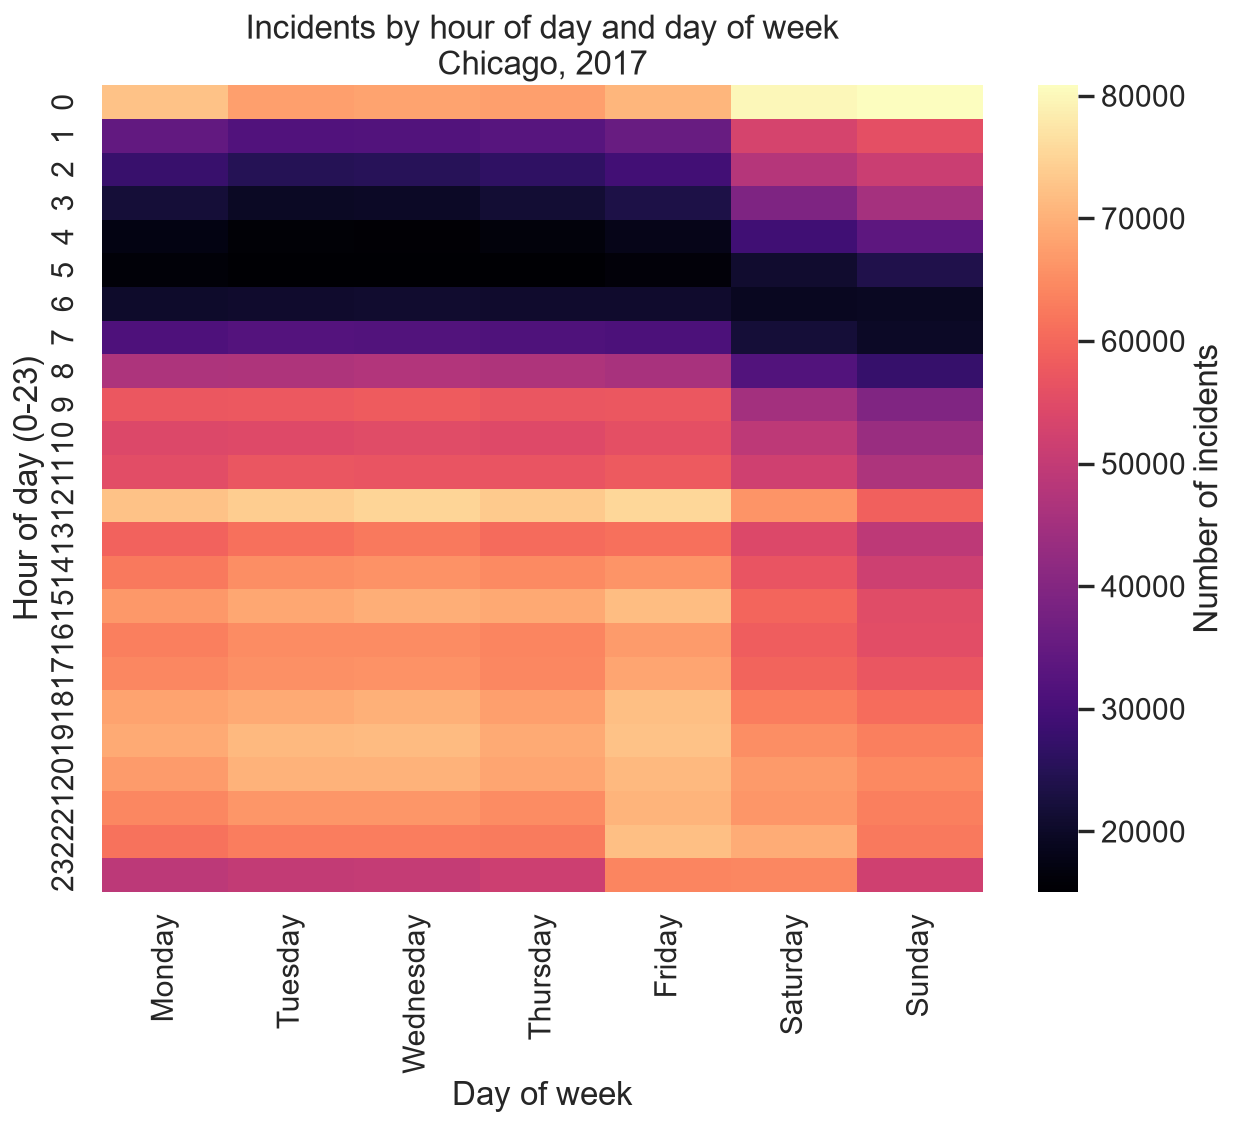

In [19]:
pivot_hour_day = df.pivot_table(index="Hour", columns="DayOfWeek",
                                 values="ID", aggfunc="count")[WEEKDAY_ORDER]

fig, ax = plt.subplots(figsize=(10, 9))
sns.heatmap(pivot_hour_day, cmap="magma", ax=ax,
            cbar_kws={"label": "Number of incidents"})
ax.set_title("Incidents by hour of day and day of week\nChicago, 2017")
ax.set_xlabel("Day of week")
ax.set_ylabel("Hour of day (0-23)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig5_hour_weekday_heatmap.png")
plt.show()


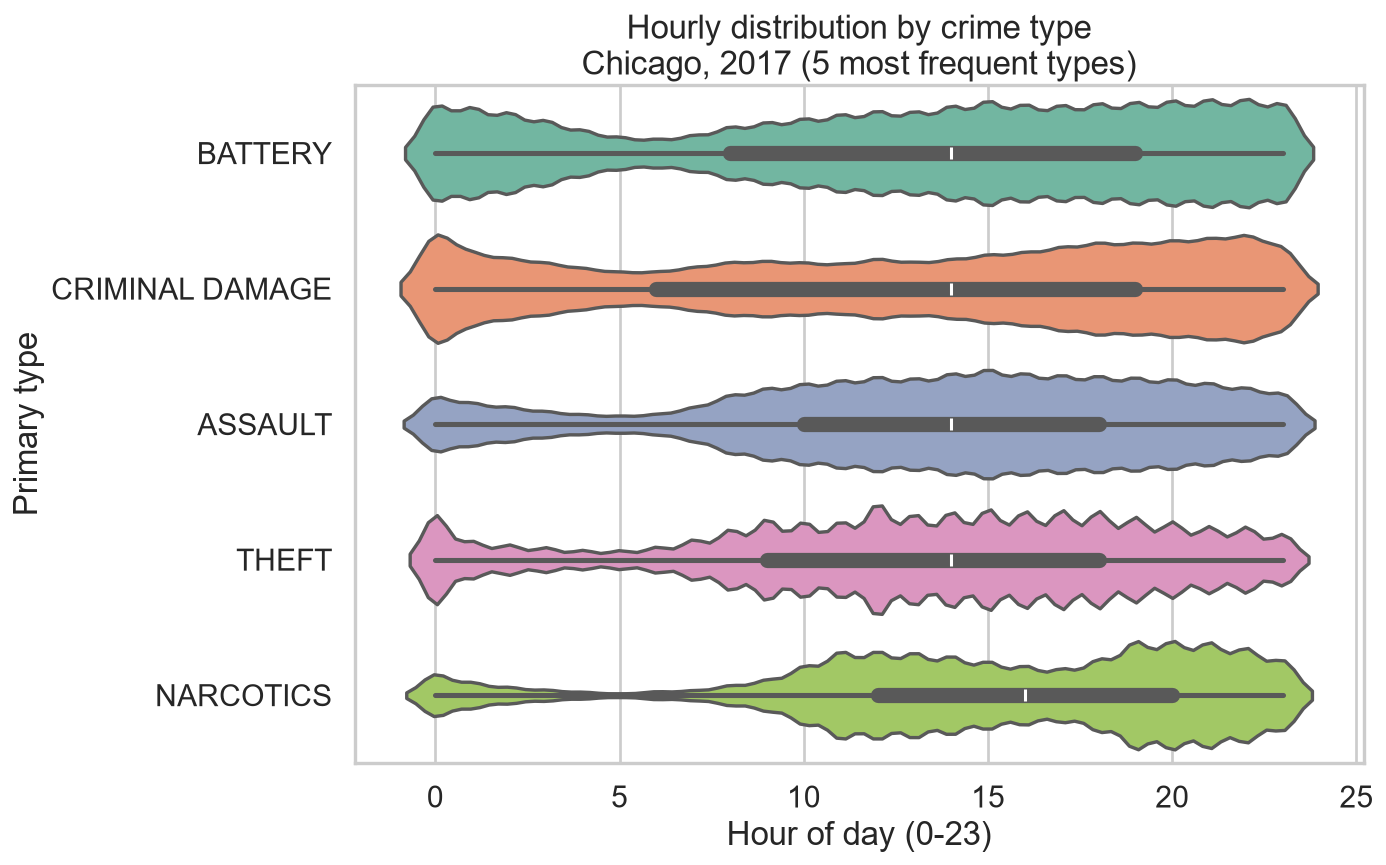

In [20]:
top5_types = df["Primary Type"].value_counts().head(5).index
subset_top5 = df[df["Primary Type"].isin(top5_types)]

fig, ax = plt.subplots(figsize=(11, 7))
sns.violinplot(data=subset_top5, x="Hour", y="Primary Type",
                hue="Primary Type", palette="Set2", legend=False,
                ax=ax, orient="h")
ax.set_title("Hourly distribution by crime type\nChicago, 2017 (5 most frequent types)")
ax.set_xlabel("Hour of day (0-23)")
ax.set_ylabel("Primary type")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig8_hour_violin_by_type.png")
plt.show()


**Finding.** Incidents rise steadily from a morning low, peak in the
afternoon/evening, and stay elevated until late night. The pattern is
similar across weekdays and weekends, but the "firing signature" differs by
crime type, as the violin plot shows.

### H3 -- Clearance rate by crime type


In [21]:
top8_types = df["Primary Type"].value_counts().head(8).index
arrest_rate = (df[df["Primary Type"].isin(top8_types)]
               .groupby("Primary Type")["Arrest"].mean()
               .sort_values(ascending=False) * 100)

contingency_h3 = pd.crosstab(df[df["Primary Type"].isin(top8_types)]["Primary Type"],
                              df[df["Primary Type"].isin(top8_types)]["Arrest"])
chi2_h3, p_h3, dof_h3, _ = stats.chi2_contingency(contingency_h3)

print(f"Chi-squared test: chi2={chi2_h3:.1f}, dof={dof_h3}, p={p_h3:.2e}")
arrest_rate.round(1)


Chi-squared test: chi2=3008883.4, dof=7, p=0.00e+00


Primary Type
NARCOTICS              99.3
BATTERY                21.6
ASSAULT                20.0
OTHER OFFENSE          17.7
THEFT                  10.8
MOTOR VEHICLE THEFT     7.4
CRIMINAL DAMAGE         6.5
BURGLARY                5.7
Name: Arrest, dtype: float64

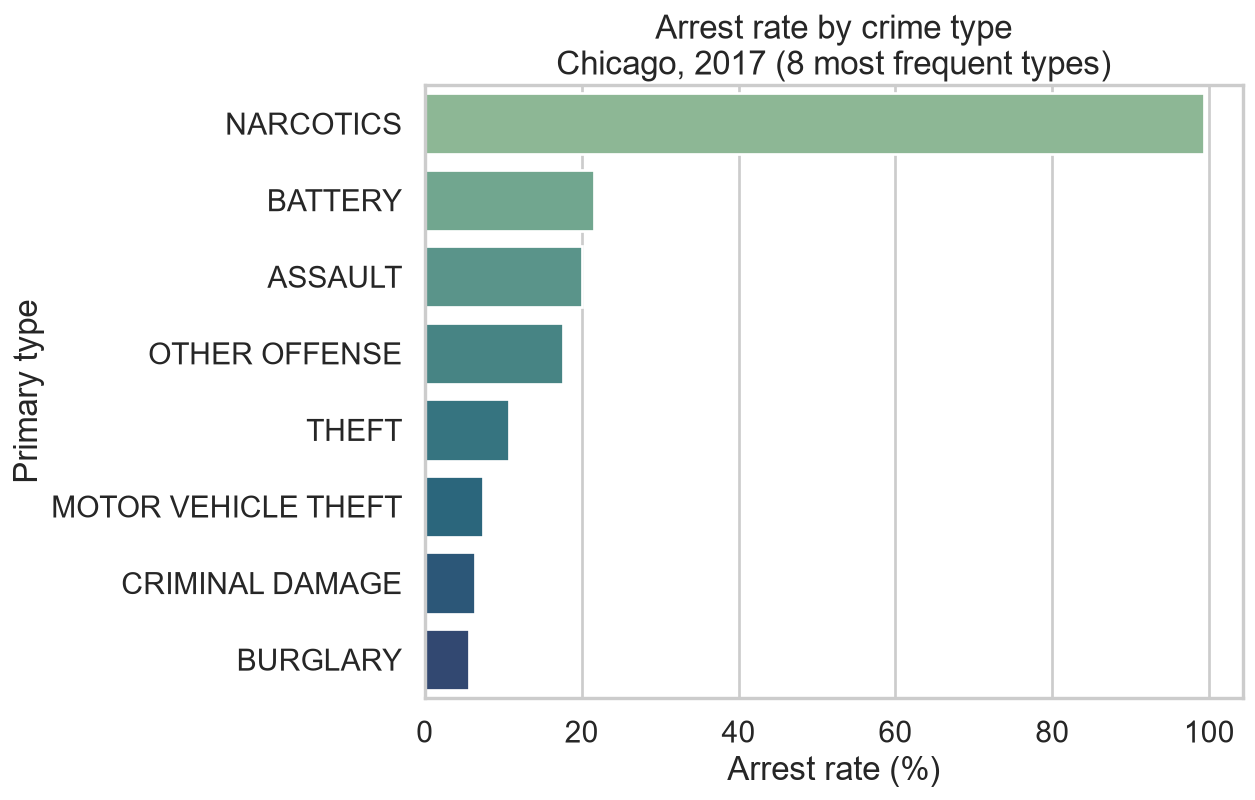

In [22]:
fig, ax = plt.subplots(figsize=(10, 6.5))
sns.barplot(x=arrest_rate.values, y=arrest_rate.index,
            hue=arrest_rate.index, palette="crest", legend=False, ax=ax)
ax.set_title("Arrest rate by crime type\nChicago, 2017 (8 most frequent types)")
ax.set_xlabel("Arrest rate (%)")
ax.set_ylabel("Primary type")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig7_arrest_rate_by_type.png")
plt.show()


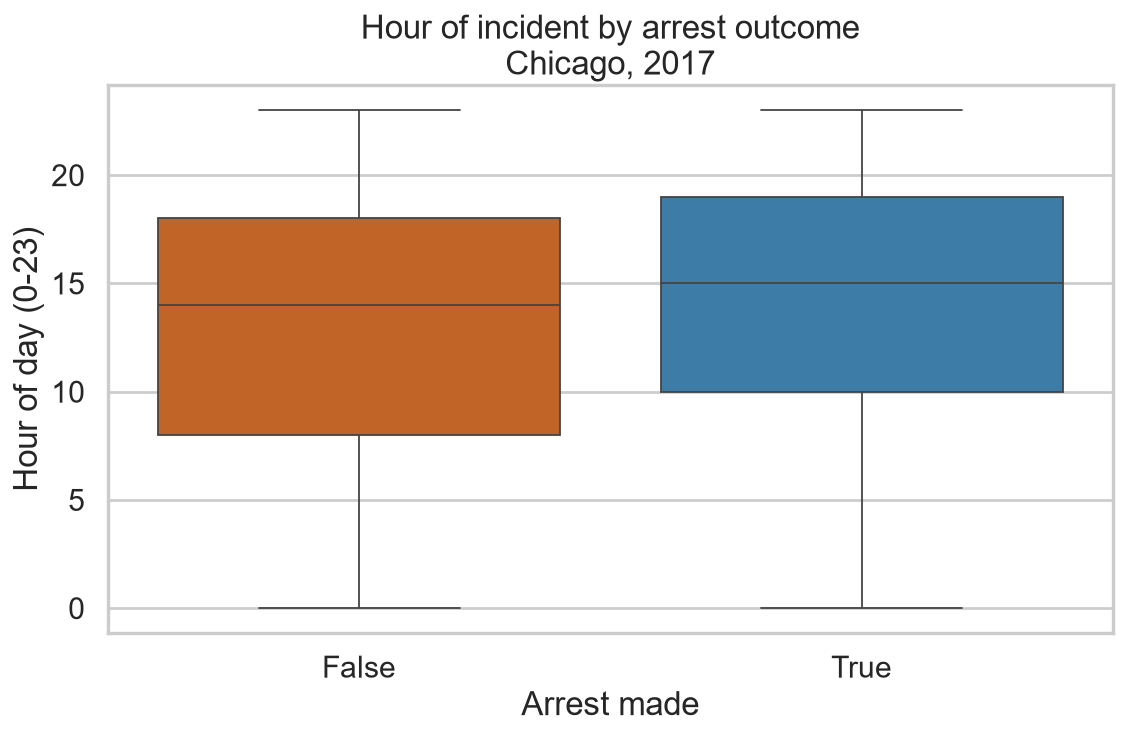

In [23]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(data=df, x="Arrest", y="Hour", hue="Arrest",
            palette=["#d95f0e", "#2c7fb8"], legend=False, ax=ax)
ax.set_title("Hour of incident by arrest outcome\nChicago, 2017")
ax.set_xlabel("Arrest made")
ax.set_ylabel("Hour of day (0-23)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig2_hour_by_arrest_boxplot.png")
plt.show()


**Finding.** The chi-squared test rejects independence between crime
type and arrest outcome with a very small p-value. Arrest rates range from
about 4% (deceptive practice, burglary) to over 20% (other offense,
battery).

### H4 -- Domestic incidents by location type


In [24]:
top6_locations = df["Location Description"].value_counts().head(6).index
domestic_rate = (df[df["Location Description"].isin(top6_locations)]
                  .groupby("Location Description")["Domestic"].mean()
                  .sort_values(ascending=False) * 100)

contingency_h4 = pd.crosstab(
    df[df["Location Description"].isin(top6_locations)]["Location Description"],
    df[df["Location Description"].isin(top6_locations)]["Domestic"]
)
chi2_h4, p_h4, dof_h4, _ = stats.chi2_contingency(contingency_h4)

print(f"Chi-squared test: chi2={chi2_h4:.1f}, dof={dof_h4}, p={p_h4:.2e}")
domestic_rate.round(1)


Chi-squared test: chi2=966299.6, dof=5, p=0.00e+00


Location Description
APARTMENT                         47.0
RESIDENCE                         38.4
SIDEWALK                          11.0
STREET                             8.2
OTHER                              6.9
PARKING LOT/GARAGE(NON.RESID.)     5.1
Name: Domestic, dtype: float64

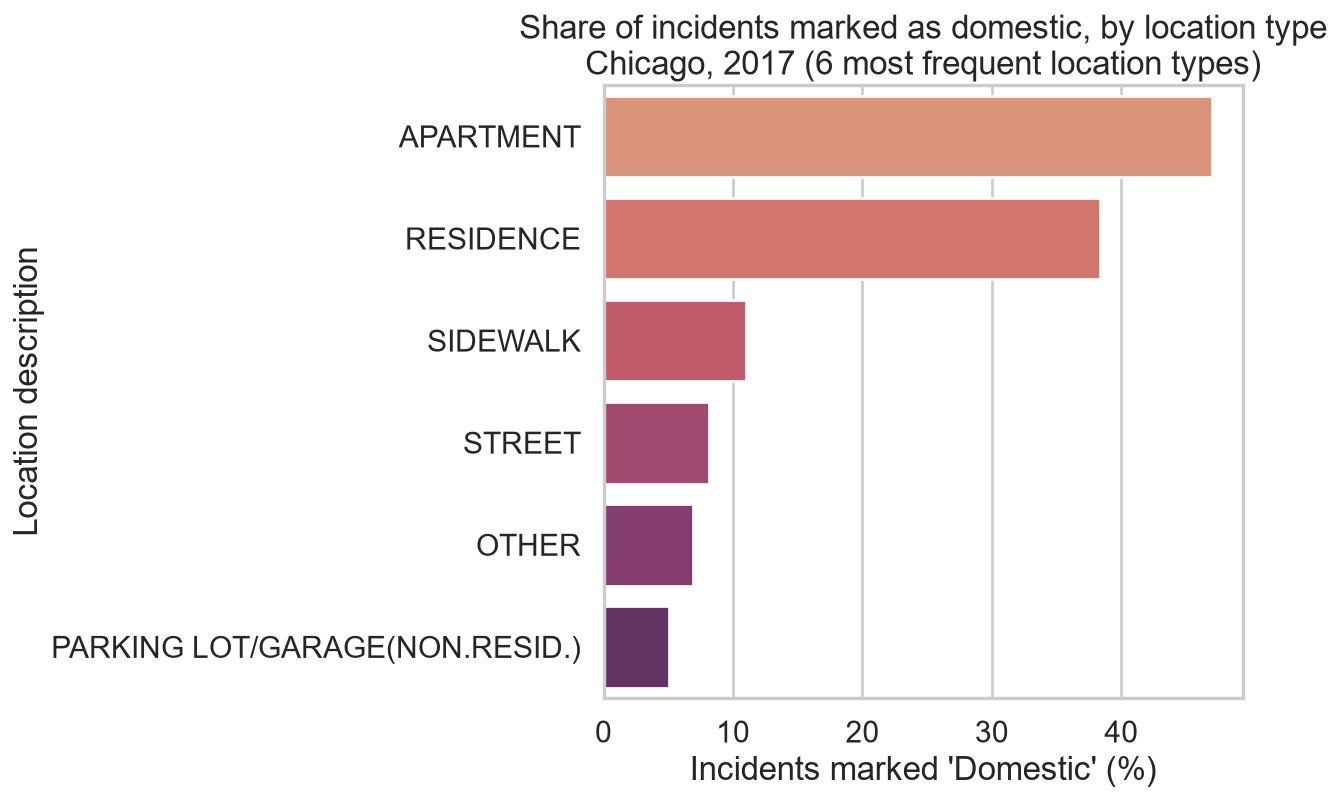

In [25]:
fig, ax = plt.subplots(figsize=(10, 6.5))
sns.barplot(x=domestic_rate.values, y=domestic_rate.index,
            hue=domestic_rate.index, palette="flare", legend=False, ax=ax)
ax.set_title("Share of incidents marked as domestic, by location type\n"
             "Chicago, 2017 (6 most frequent location types)")
ax.set_xlabel("Incidents marked 'Domestic' (%)")
ax.set_ylabel("Location description")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig9_domestic_rate_by_location.png")
plt.show()


**Finding.** Domestic incidents are heavily concentrated in homes:
43% of apartment incidents and 34% of residence incidents are flagged as
domestic, versus under 10% on the street. This also acts as a consistency
check on the dataset, since it matches well-established criminological
knowledge.


## 8. Beyond aggregate views: NMF-based pattern detection

A simple hour-by-weekday heatmap treats the city as a single unit. Following
CrimAnalyzer's approach, non-negative matrix factorization (NMF) is applied
to a Community Area x Hour count matrix to recover a small number of latent
spatio-temporal patterns, each with its own hourly signature and its own set
of characteristic areas. This surfaces local patterns that a single
city-wide aggregate would hide.


In [26]:
area_hour_matrix = (df_spatial
                     .pivot_table(index="Community Area", columns="Hour",
                                  values="ID", aggfunc="count", fill_value=0))

N_COMPONENTS = 4
nmf_model = NMF(n_components=N_COMPONENTS, init="nndsvda",
                 random_state=RANDOM_STATE, max_iter=500)
area_weights = nmf_model.fit_transform(area_hour_matrix.values)
hour_signatures = nmf_model.components_

pattern_labels = [f"Pattern {i + 1}" for i in range(N_COMPONENTS)]
area_weights_df = pd.DataFrame(area_weights, index=area_hour_matrix.index,
                                columns=pattern_labels)
hour_signatures_df = pd.DataFrame(hour_signatures, index=pattern_labels,
                                   columns=area_hour_matrix.columns)
area_weights_df.to_csv(TABLES_DIR / "nmf_area_weights.csv")
hour_signatures_df.to_csv(TABLES_DIR / "nmf_hour_signatures.csv")


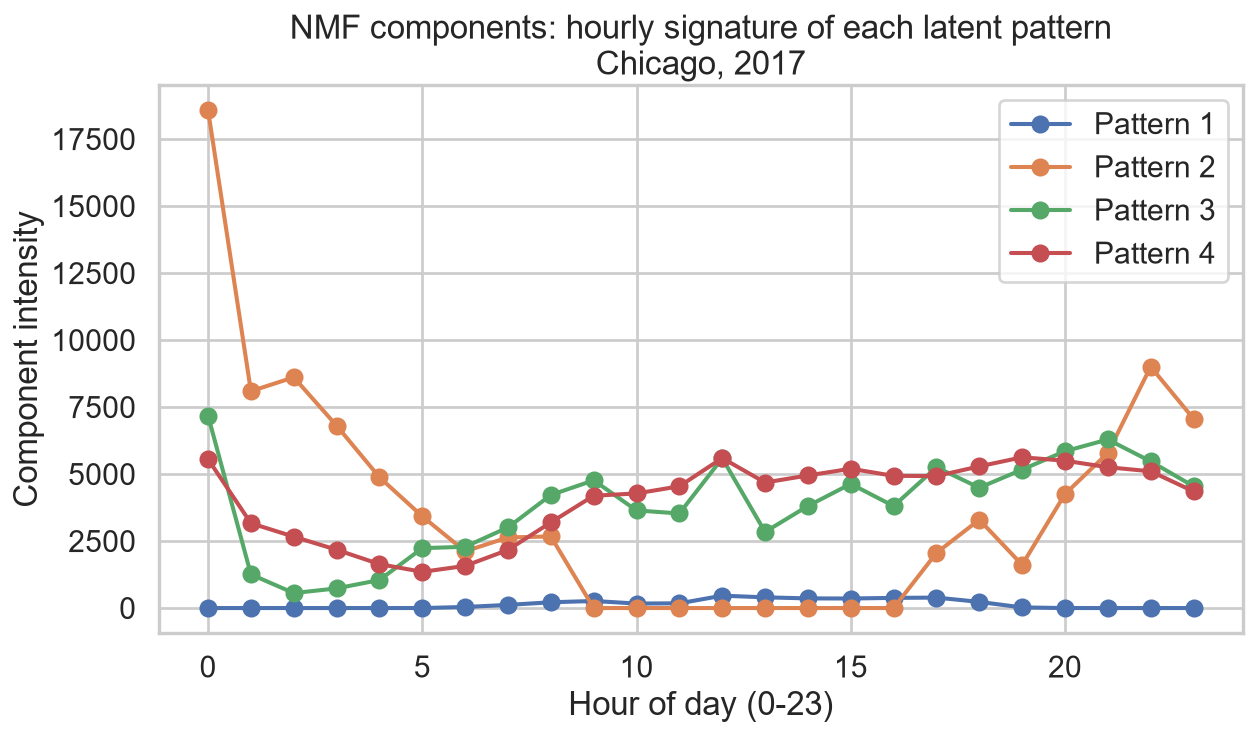

In [27]:
fig, ax = plt.subplots(figsize=(10, 6))
for label in pattern_labels:
    ax.plot(hour_signatures_df.columns, hour_signatures_df.loc[label],
            marker="o", label=label)
ax.set_title("NMF components: hourly signature of each latent pattern\nChicago, 2017")
ax.set_xlabel("Hour of day (0-23)")
ax.set_ylabel("Component intensity")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig11_nmf_hour_signatures.png")
plt.show()


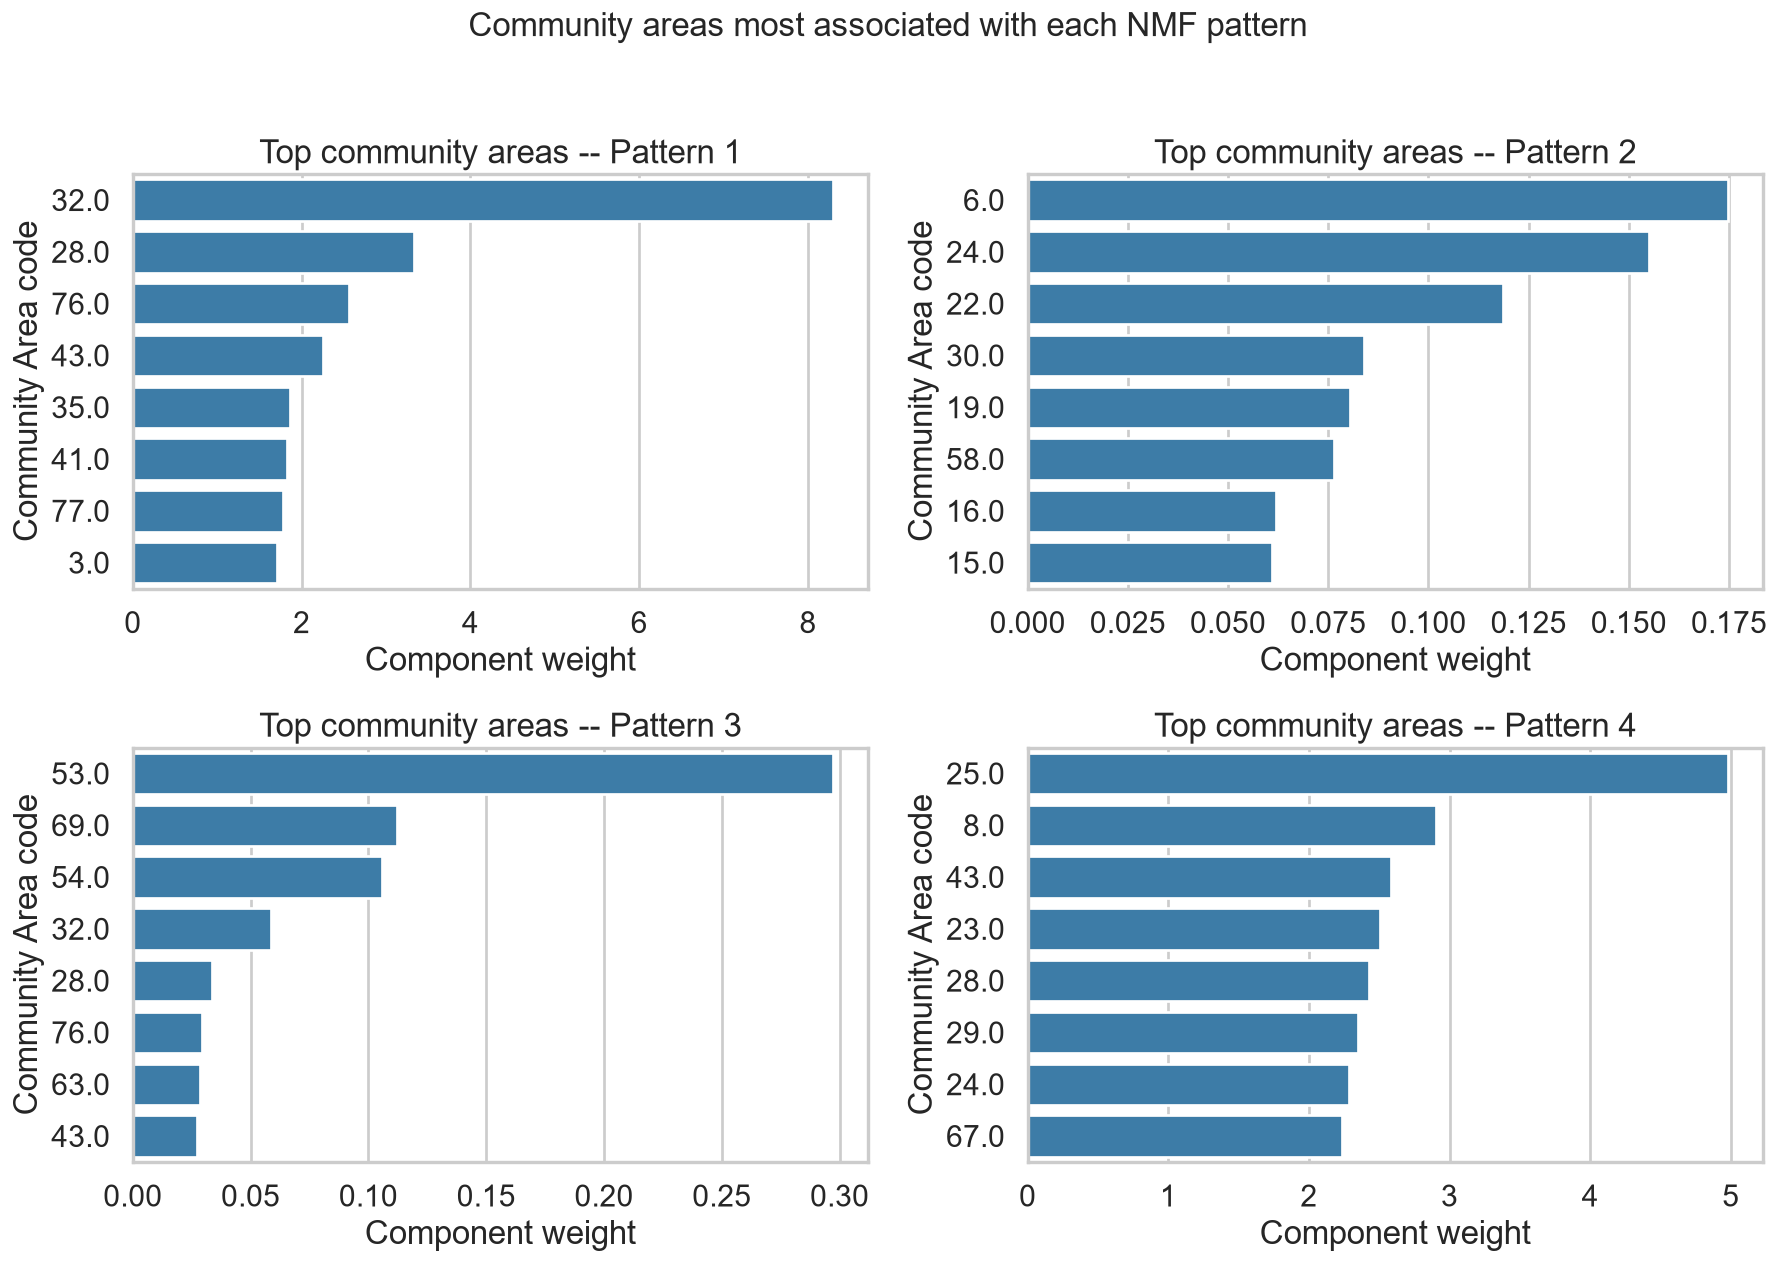

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for label, ax in zip(pattern_labels, axes.flat):
    top_areas = area_weights_df[label].sort_values(ascending=False).head(8)
    sns.barplot(x=top_areas.values, y=top_areas.index.astype(str),
                color="#2c7fb8", ax=ax)
    ax.set_title(f"Top community areas -- {label}")
    ax.set_xlabel("Component weight")
    ax.set_ylabel("Community Area code")
fig.suptitle("Community areas most associated with each NMF pattern", fontsize=18)
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(FIGURES_DIR / "fig12_nmf_top_areas.png")
plt.show()


**Finding.** Each component isolates a distinct hourly signature (for
example, a night-weighted pattern versus an afternoon-weighted one) and a
distinct set of community areas. This is the kind of decomposition a
Visual Analytics system should expose interactively, letting an analyst
select a pattern and see both its temporal shape and its spatial footprint
at once, rather than only a single static heatmap.


## 9. Summary dashboard

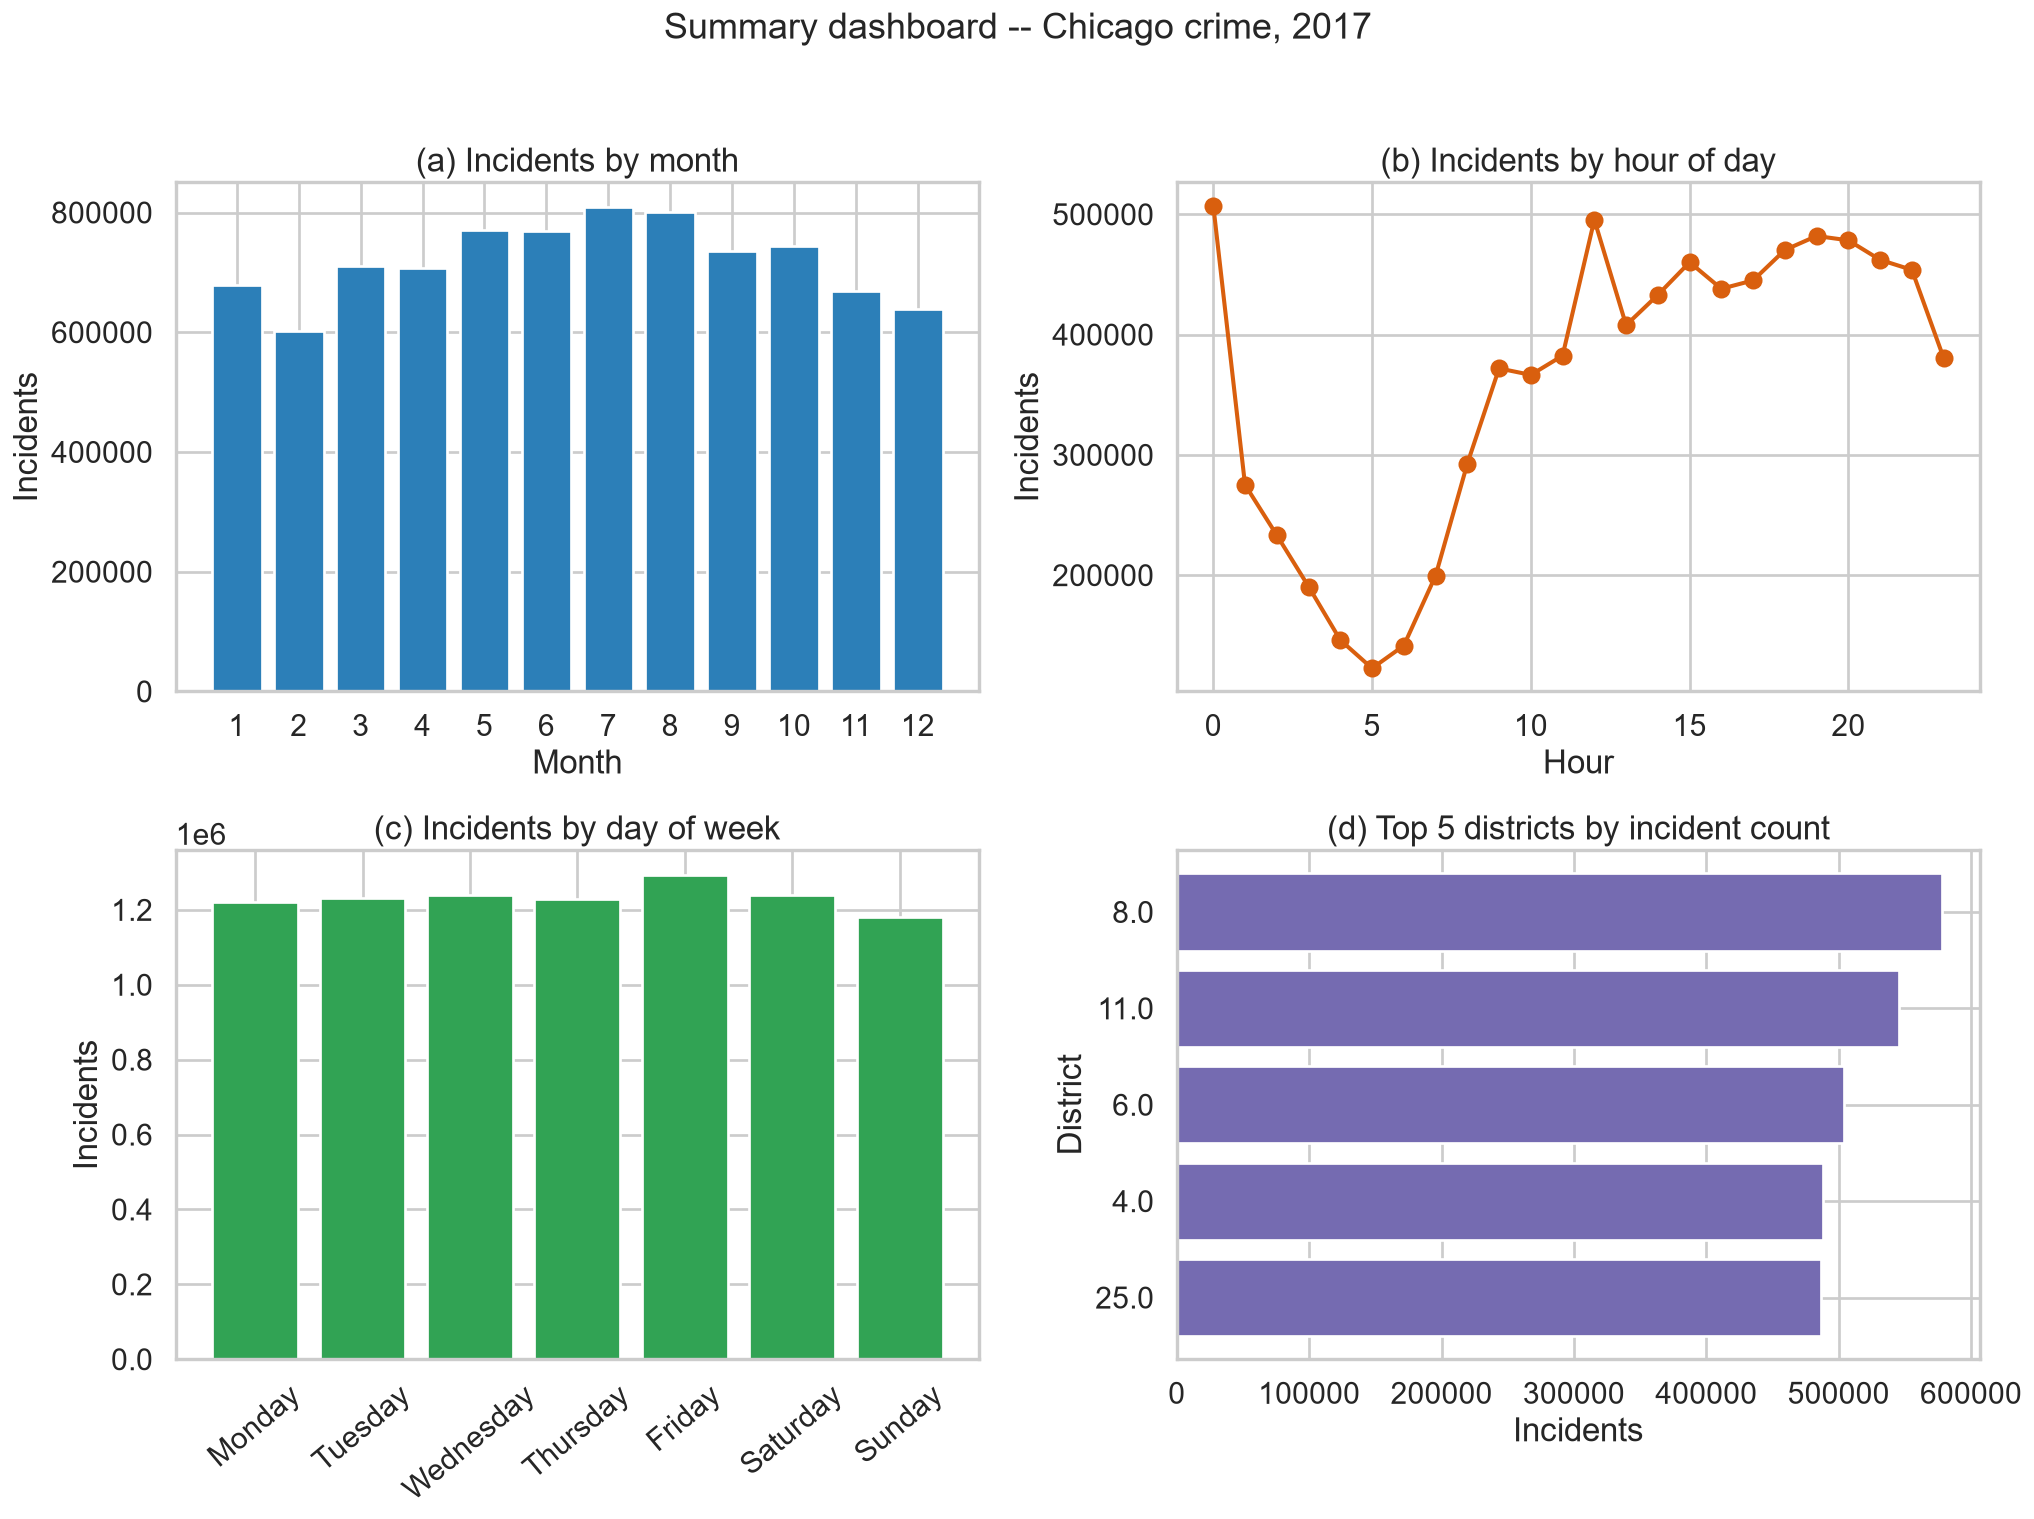

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

axes[0, 0].bar(monthly_counts.index, monthly_counts.values, color="#2c7fb8")
axes[0, 0].set_title("(a) Incidents by month")
axes[0, 0].set_xlabel("Month")
axes[0, 0].set_ylabel("Incidents")
axes[0, 0].set_xticks(range(1, 13))

axes[0, 1].plot(hourly_counts.index, hourly_counts.values, marker="o", color="#d95f0e")
axes[0, 1].set_title("(b) Incidents by hour of day")
axes[0, 1].set_xlabel("Hour")
axes[0, 1].set_ylabel("Incidents")

weekday_counts = df["DayOfWeek"].value_counts().reindex(WEEKDAY_ORDER)
axes[1, 0].bar(weekday_counts.index, weekday_counts.values, color="#31a354")
axes[1, 0].set_title("(c) Incidents by day of week")
axes[1, 0].set_ylabel("Incidents")
axes[1, 0].tick_params(axis="x", rotation=40)

top5_districts = district_counts.head(5)
axes[1, 1].barh(top5_districts.index.astype(str), top5_districts.values, color="#756bb1")
axes[1, 1].invert_yaxis()
axes[1, 1].set_title("(d) Top 5 districts by incident count")
axes[1, 1].set_xlabel("Incidents")
axes[1, 1].set_ylabel("District")

fig.suptitle("Summary dashboard -- Chicago crime, 2017", fontsize=20)
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(FIGURES_DIR / "fig10_dashboard.png")
plt.show()


## 10. Export cleaned dataset

In [30]:
clean_path = OUTPUT_DIR / "chicago_crimes_2017_clean.csv"
df.to_csv(clean_path, index=False)
print("Clean dataset written to:", clean_path.resolve())
print("Figures written to:", FIGURES_DIR.resolve())
print("Tables written to:", TABLES_DIR.resolve())


Clean dataset written to: C:\Users\aleax\Desktop\data_science_final\outputs\chicago_crimes_2017_clean.csv
Figures written to: C:\Users\aleax\Desktop\data_science_final\outputs\figures
Tables written to: C:\Users\aleax\Desktop\data_science_final\outputs\tables
